# **Department of CSE(Data Sceince)**

Name: Prathiksha V

USN: 1VI23CD035

Semester: VII

### BAD702 – Statistical Machine Learning for Data Science

# *Statistical Analysis and Machine Learning-Based Prediction of Air Quality Across Indian Regions*

**Dataset:** `aqi.csv`  

This project analyses air-quality patterns across Indian states and areas using descriptive statistics, exploratory data analysis, hypothesis testing, regression and classification.

> **Important methodological note:** The dataset contains AQI, geographic information, monitoring-station counts and prominent pollutant labels, but it does **not** contain numerical pollutant concentration columns such as PM2.5, PM10, NO₂, SO₂ or CO. Therefore, pollutant concentrations are not invented or treated as numerical predictors.


## 1. Problem Definition

Air quality varies substantially across regions and time. Reliable statistical analysis can help identify where and when air-quality conditions are more severe and can support data-driven monitoring.

The problem addressed in this project is:

**How does air quality vary across Indian regions and time, and can the observed AQI level and air-quality status be predicted using the non-leaking information available in the dataset?**

## 2. Objectives

1. Understand the structure and quality of the Indian AQI dataset.
2. Calculate descriptive statistics for AQI.
3. Study AQI distributions and regional/temporal patterns.
4. Analyse the frequency and relationship of prominent pollutants with AQI.
5. Test whether AQI differs significantly across seasons and states.
6. Build a Multiple Linear Regression model for numerical AQI prediction.
7. Build Logistic Regression and Random Forest models for air-quality-status classification.
8. Evaluate and compare the models using appropriate performance measures.
9. Draw statistically supported conclusions.

## 3. Research Questions

**RQ1:** What are the distribution and central tendencies of AQI across the dataset?

**RQ2:** Does AQI vary significantly across seasons?

**RQ3:** Does AQI vary significantly across Indian states?

**RQ4:** Which prominent pollutants occur most frequently, and how does mean AQI differ when each pollutant is reported?

**RQ5:** Can numerical AQI be predicted using location, time and monitoring-station information?

**RQ6:** Can the air-quality status category be classified using the same non-leaking information?

## 4. Dataset Description

The analysis uses the supplied `aqi.csv` file.

| Variable | Description | Role |
|---|---|---|
| `date` | Date of observation | Temporal feature |
| `state` | Indian state/region | Categorical feature |
| `area` | City/area | Categorical feature |
| `number_of_monitoring_stations` | Number of monitoring stations | Numerical feature |
| `prominent_pollutants` | Pollutant(s) identified as prominent | Categorical/descriptive feature |
| `aqi_value` | Numerical Air Quality Index | Regression target |
| `air_quality_status` | AQI category | Classification target |
| `unit` | Unit description supplied with the dataset | Metadata |
| `note` | Additional note field | Removed if empty |

**Leakage control:** `aqi_value` is not used as an input when predicting `air_quality_status`, because the status category is derived from AQI ranges. Similarly, `air_quality_status` and `prominent_pollutants` are not used as numerical predictors of AQI.

## 5. Import Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import f_oneway

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Libraries imported successfully.")

Libraries imported successfully.


## 6. Load the Dataset

In [ ]:
FILE_PATH = "aqi.csv"

df = pd.read_csv(FILE_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (235785, 9)


,date,state,area,number_of_monitoring_stations,prominent_pollutants,aqi_value,air_quality_status,unit,note
0,30-04-2025,Maharashtra,Amravati,2,PM10,78,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
1,30-04-2025,Bihar,Purnia,1,CO,56,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
2,30-04-2025,Madhya Pradesh,Katni,1,O3,98,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
3,30-04-2025,Chhattisgarh,Tumidih,1,PM10,103,Moderate,number_of_monitoring_stations in Absolute Numb...,NaN
4,30-04-2025,Assam,Byrnihat,1,PM2.5,61,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN


## 7. Initial Dataset Inspection

### Initial Data Inspection

This section checks the dataset's structure, data types, missing values, and duplicate entries to prepare for cleaning.

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df.info()

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['date', 'state', 'area', 'number_of_monitoring_stations', 'prominent_pollutants', 'aqi_value', 'air_quality_status', 'unit', 'note']

Data types:


,Data Type
date,object
state,object
area,object
number_of_monitoring_stations,int64
prominent_pollutants,object
aqi_value,int64
air_quality_status,object
unit,object
note,float64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235785 entries, 0 to 235784
Data columns (total 9 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   date                           235785 non-null  object 
 1   state                          235785 non-null  object 
 2   area                           235785 non-null  object 
 3   number_of_monitoring_stations  235785 non-null  int64  
 4   prominent_pollutants           235785 non-null  object 
 5   aqi_value                      235785 non-null  int64  
 6   air_quality_status             235785 non-null  object 
 7   unit                           235785 non-null  object 
 8   note                           0 non-null       float64
dtypes: float64(1), int64(2), object(6)
memory usage: 16.2+ MB

Duplicate rows: 0


### Inspection Results

The dataset contains 235,785 rows and 9 original columns. There are no duplicate rows in the raw file. The `note` column is entirely empty, while the two main numerical fields are `number_of_monitoring_stations` and `aqi_value`.


In [ ]:
# Convert date safely. The source uses day-month-year formatting.
df["date"] = pd.to_datetime(df["date"], dayfirst=True, errors="coerce")

print("Parsed date range:")
print(df["date"].min().date(), "to", df["date"].max().date())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nUnique states:", df["state"].nunique())
print("Unique areas:", df["area"].nunique())
print("Unique AQI statuses:", df["air_quality_status"].nunique())

Parsed date range:
2022-04-01 to 2025-04-30

Missing values:


,Missing Values
date,0
state,0
area,0
number_of_monitoring_stations,0
prominent_pollutants,0
aqi_value,0
air_quality_status,0
unit,0
note,235785



Unique states: 32
Unique areas: 291
Unique AQI statuses: 6


### Date Parsing and Initial Gaps

The source date strings are converted using day-first parsing. The executed dataset covers **1 April 2022 to 30 April 2025**, with 32 states/regions, 291 areas and 6 air-quality-status categories.


## 8. Data Preprocessing

The preprocessing steps are intentionally conservative:

- Parse the date column.
- Remove rows with invalid dates, if any.
- Remove exact duplicate rows.
- Convert numerical columns to numeric form.
- Remove `note` when it contains no useful information.
- Create year, month, day-of-week and season features.
- Keep the original AQI status as the classification target.

### Data Preprocessing Steps

Data is copied, numerical columns are converted, rows with critical missing values are removed, duplicates are dropped, the empty `note` column is removed, and new temporal features (`year`, `month`, `day_of_week`, `day_name`, `season`) are created.

In [ ]:
# Work on a copy
data = df.copy()

# Numeric conversion
data["aqi_value"] = pd.to_numeric(data["aqi_value"], errors="coerce")
data["number_of_monitoring_stations"] = pd.to_numeric(
    data["number_of_monitoring_stations"], errors="coerce"
)

# Remove invalid essential records
data = data.dropna(subset=[
    "date", "state", "area",
    "number_of_monitoring_stations",
    "aqi_value", "air_quality_status"
]).copy()

# Remove duplicates
before = len(data)
data = data.drop_duplicates().copy()
removed_duplicates = before - len(data)

# Remove completely empty note column
if "note" in data.columns and data["note"].isna().all():
    data = data.drop(columns=["note"])

# Time features
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month
data["day_of_week"] = data["date"].dt.dayofweek
data["day_name"] = data["date"].dt.day_name()

def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

data["season"] = data["month"].apply(assign_season)

print("Rows removed as duplicates:", removed_duplicates)
print("Final shape:", data.shape)
print("Date range:", data["date"].min().date(), "to", data["date"].max().date())

Rows removed as duplicates: 0
Final shape: (235785, 13)
Date range: 2022-04-01 to 2025-04-30


### Preprocessing Results

1.  **Numeric Conversion:** `aqi_value` and `number_of_monitoring_stations` are now numeric.
2.  **Missing Values:** Critical missing values were handled. No additional duplicates were found.
3.  **`note` Column:** The `note` column was dropped.
4.  **New Features:** Time-based features were successfully added.


## 9. Data Quality Verification

### Data Quality Verification

Checks for remaining missing values, duplicates, and verifies the `aqi_value` and `air_quality_status` consistency.

In [ ]:
print("Missing values after preprocessing:")
display(data.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows after preprocessing:", data.duplicated().sum())

print("\nAQI range:", data["aqi_value"].min(), "to", data["aqi_value"].max())

print("\nAQI status ranges:")
display(
    data.groupby("air_quality_status")["aqi_value"]
    .agg(["count", "min", "max", "mean", "median"])
    .sort_values("min")
)

Missing values after preprocessing:


,Missing Values
date,0
state,0
area,0
number_of_monitoring_stations,0
prominent_pollutants,0
aqi_value,0
air_quality_status,0
unit,0
year,0
month,0



Duplicate rows after preprocessing: 0

AQI range: 3 to 500

AQI status ranges:


,count,min,max,mean,median
air_quality_status,,,,,
Good,41971,3,50,38.682,40.000
Satisfactory,88897,51,100,74.065,73.000
Moderate,77537,101,200,138.589,133.000
Poor,21154,201,300,241.300,237.000
Very Poor,5671,301,400,336.441,331.000
Severe,555,398,500,425.694,420.000


### Quality Verification Results

1.  **Missing Values & Duplicates:** No missing values or duplicate rows remain.
2.  **AQI Range:** `aqi_value` spans from **3.0 to 500.0**.
3.  **AQI Status:** The `air_quality_status` categories align logically with `aqi_value` ranges (e.g., 'Good' has low AQI, 'Severe' has high AQI).

### AQI Status Validation

The dataset's status categories should correspond to the standard AQI bands represented in the file. We verify the observed minimum and maximum AQI for every status rather than assuming the labels are correct.

## 10. Descriptive Statistics

### Descriptive Statistics for AQI

This section calculates basic statistics for `aqi_value` (mean, median, mode, spread, etc.) to understand its distribution (RQ1).

In [ ]:
aqi = data["aqi_value"]

mode_values = aqi.mode().tolist()

descriptive = pd.Series({
    "Count": aqi.count(),
    "Mean": aqi.mean(),
    "Median": aqi.median(),
    "Mode": ", ".join(map(str, mode_values[:10])),
    "Variance": aqi.var(),
    "Standard Deviation": aqi.std(),
    "Minimum": aqi.min(),
    "Q1 (25%)": aqi.quantile(0.25),
    "Q2 (50%)": aqi.quantile(0.50),
    "Q3 (75%)": aqi.quantile(0.75),
    "Maximum": aqi.max(),
    "IQR": aqi.quantile(0.75) - aqi.quantile(0.25)
})

display(descriptive.to_frame("Value"))

,Value
Count,235785
Mean,111.127
Median,92.000
Mode,46
Variance,"5,104.724"
Standard Deviation,71.447
Minimum,3
Q1 (25%),59.000
Q2 (50%),92.000
Q3 (75%),142.000


### AQI Statistics Interpretation

- **Mean AQI:** 111.13
- **Median AQI:** 92.00
- **Mode:** 46
- **Standard deviation:** 71.45
- **Range:** 3 to 500
- **IQR:** 83, so the middle 50% of observations lie between AQI 59 and 142.

The mean is higher than the median, which is consistent with the right-skewed distribution observed in the histogram.


## 11. AQI Distribution

### AQI Distribution Visualization

Visualizes `aqi_value` distribution using a histogram and boxplot to check shape, central tendency, spread, and outliers (RQ1).

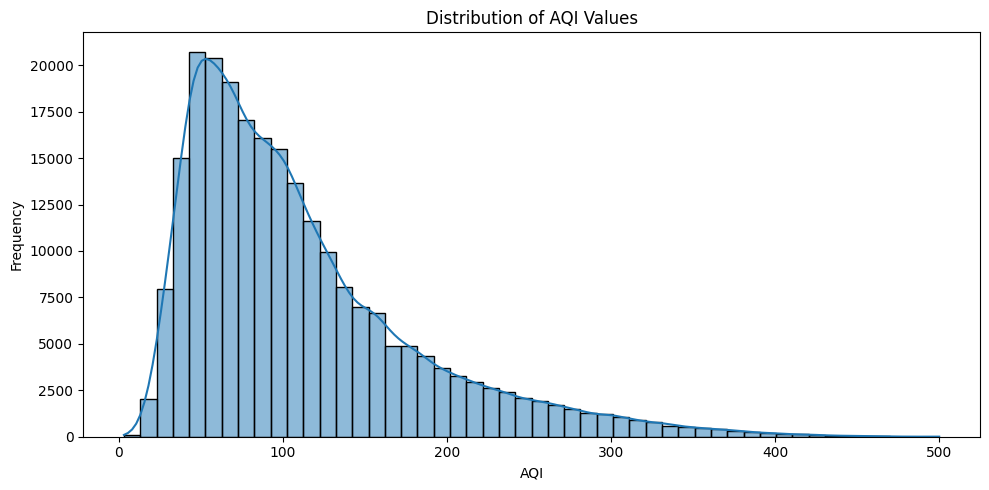

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(data["aqi_value"], bins=50, kde=True)
plt.title("Distribution of AQI Values")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Histogram Observations

The histogram shows a **right-skewed** distribution, peaking around 50-70 AQI. This means lower AQI values (better air quality) are more common, but there are instances of much higher (poorer) air quality. This matches the descriptive statistics.

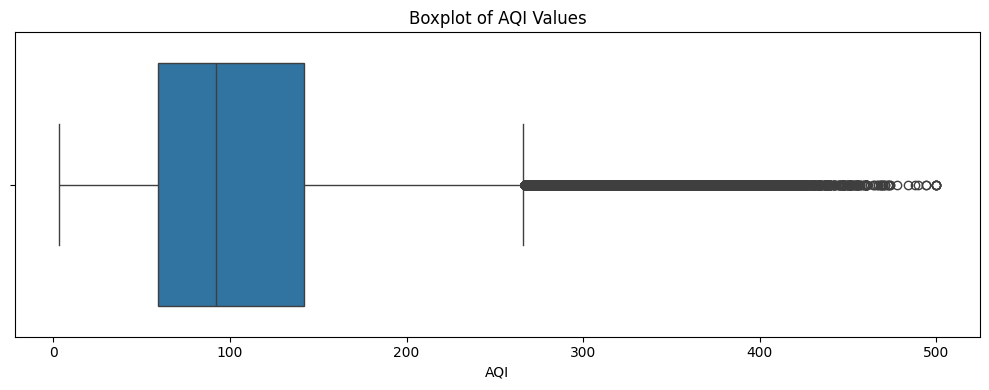

In [ ]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=data["aqi_value"])
plt.title("Boxplot of AQI Values")
plt.xlabel("AQI")
plt.tight_layout()
plt.show()

### Boxplot Observations

The boxplot confirms the **right-skewness** and reveals many **outliers** extending to 500 AQI, signifying severe air quality events. Most AQI values fall between 55 and 130, as seen in the IQR.

## 12. Air-Quality Status Distribution

### Air-Quality Status Distribution

Analyzes the frequency of each `air_quality_status` category to understand overall air quality patterns and implications for classification models.

,Count
air_quality_status,
Good,41971
Satisfactory,88897
Moderate,77537
Poor,21154
Very Poor,5671
Severe,555


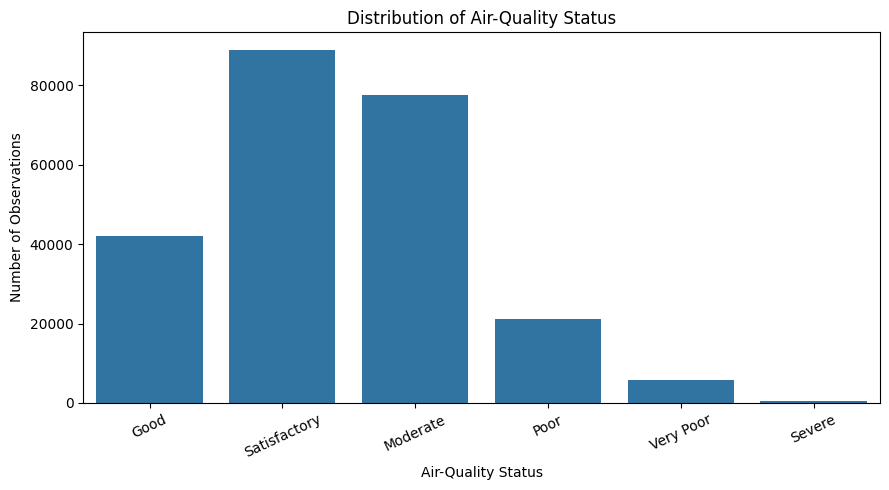

In [ ]:
status_order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

status_counts = data["air_quality_status"].value_counts()
status_counts = status_counts.reindex(status_order).fillna(0)

display(status_counts.to_frame("Count"))

plt.figure(figsize=(9, 5))
sns.barplot(x=status_counts.index, y=status_counts.values)
plt.title("Distribution of Air-Quality Status")
plt.xlabel("Air-Quality Status")
plt.ylabel("Number of Observations")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### Status Distribution Observations

1.  **Dominant:** 'Satisfactory' and 'Moderate' are most frequent, followed by 'Good'.
2.  **Less Frequent:** 'Poor', 'Very Poor', and 'Severe' are rare, as expected for critical events.
3.  **Imbalance:** The data is highly imbalanced, which needs careful handling for classification tasks, especially for predicting rarer statuses.

## 13. State-Wise AQI Analysis

### State-Wise AQI Analysis

Explores AQI variation across Indian states by summarizing `aqi_value` by `state` (RQ3), identifying regions with higher or lower pollution.

In [ ]:
state_summary = (
    data.groupby("state")["aqi_value"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

display(state_summary.head(15))

,count,mean,median,std,min,max
state,,,,,,
Delhi,1125,206.417,194.000,101.467,44,494
Jharkhand,721,164.940,154.000,58.587,20,436
Himachal Pradesh,1066,160.257,151.000,73.093,24,438
Bihar,21553,157.158,132.000,93.904,11,488
Chandigarh,1125,141.562,127.000,73.592,32,412
Haryana,21706,140.853,120.000,80.655,17,469
Rajasthan,26585,127.987,113.000,65.123,18,452
Tripura,1035,126.698,95.000,84.069,15,362
Uttar Pradesh,21609,126.424,108.000,76.152,13,494


### State-Wise AQI Summary Observations

The state-wise summary shows substantial geographical variation in AQI. In the executed results, Delhi has the highest mean AQI among the listed states, followed by Jharkhand and Himachal Pradesh. Differences in observation counts should also be considered when comparing state-level averages.


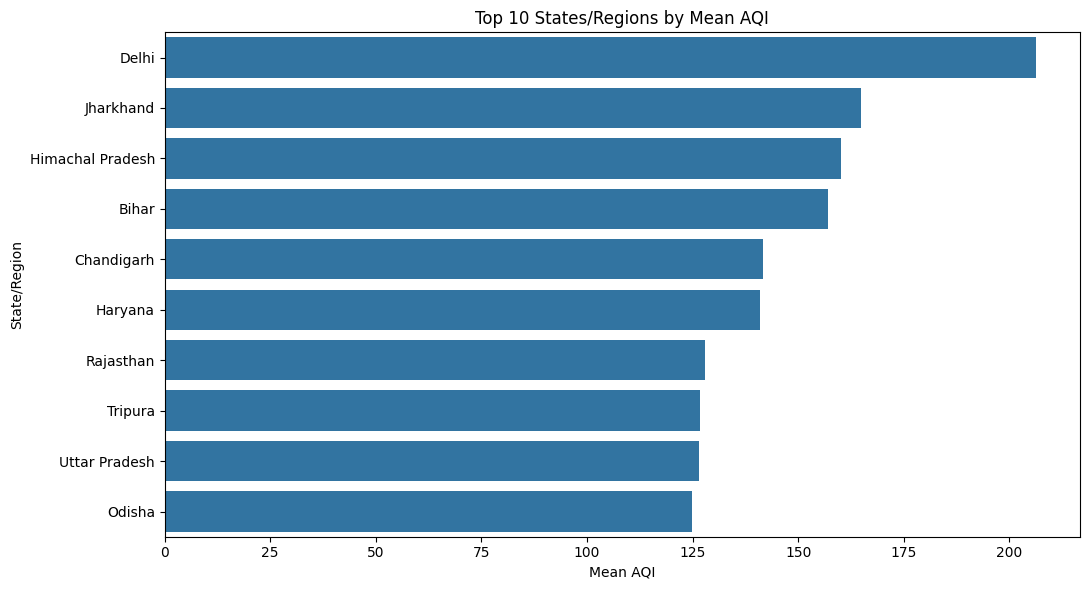

In [ ]:
top_states = state_summary.head(10)

plt.figure(figsize=(11, 6))
sns.barplot(x=top_states["mean"], y=top_states.index)
plt.title("Top 10 States/Regions by Mean AQI")
plt.xlabel("Mean AQI")
plt.ylabel("State/Region")
plt.tight_layout()
plt.show()

### Top 10 States by Mean AQI Observations

The executed ranking shows Delhi as the highest among the top listed states by mean AQI, followed by Jharkhand, Himachal Pradesh, Bihar and Chandigarh. These results indicate substantial geographical differences in observed AQI.


## 14. Area-Wise AQI Analysis

Because the dataset contains many areas, the analysis reports the areas with the highest and lowest mean AQI while requiring a minimum number of observations for stability.

### Area-Wise AQI Analysis

Identifies localized AQI hotspots or clean areas within states by looking at `aqi_value` grouped by `area`. Only areas with >= 30 observations are included for stable insights (RQ3).

In [ ]:
area_summary = (
    data.groupby("area")["aqi_value"]
    .agg(["count", "mean", "median", "std"])
)

stable_areas = area_summary[area_summary["count"] >= 30].copy()

print("Highest mean AQI areas:")
display(stable_areas.sort_values("mean", ascending=False).head(10))

print("Lowest mean AQI areas:")
display(stable_areas.sort_values("mean", ascending=True).head(10))

Highest mean AQI areas:


,count,mean,median,std
area,,,,
Byrnihat,656,239.995,250.500,94.686
Begusarai,582,206.680,186.500,124.577
Delhi,1125,206.417,194.000,101.467
Greater Noida,1123,201.602,192.000,91.632
Sri Ganganagar,709,197.939,186.000,80.913
Gurugram,1120,190.848,185.000,81.283
Darbhanga,256,190.090,129.000,133.986
Dharuhera,764,185.723,180.000,89.127
NOIDA,1124,183.989,167.000,90.881


Lowest mean AQI areas:


,count,mean,median,std
area,,,,
Tirunelveli,227,32.110,31.000,6.121
Madikeri,1062,37.808,36.000,15.887
Chamarajanagar,1075,43.059,43.000,4.864
Palkalaiperur,520,43.325,41.000,18.826
Thanjavur,162,44.722,44.000,14.637
Bagalkot,1025,46.457,46.000,5.717
Ernakulam,198,46.939,45.000,13.887
Aizawl,1000,47.247,37.000,30.723
Chikkamagaluru,937,47.456,45.000,14.908


### Area-Wise AQI Observations

Using a minimum of 30 observations per area, the executed results show substantial local variation. Byrnihat has the highest mean AQI among the listed areas, while Tirunelveli has the lowest. The minimum-observation rule improves the stability of these comparisons.


## 15. Temporal Analysis

### Temporal Analysis

Examines how AQI changes monthly and seasonally to identify patterns and trends (RQ2).

In [ ]:
monthly_summary = (
    data.groupby("month")["aqi_value"]
    .agg(["count", "mean", "median", "std"])
)

display(monthly_summary)

,count,mean,median,std
month,,,,
1,20151,152.393,131.000,84.203
2,18653,124.850,110.000,64.533
3,21017,109.468,98.000,53.561
4,24469,114.050,100.000,61.234
5,18100,110.014,97.000,59.549
6,17555,93.475,79.000,56.740
7,18303,62.844,55.000,34.595
8,18536,65.542,57.000,33.782
9,18499,67.627,59.000,35.899


### Monthly AQI Summary Observations

1.  **Seasonal Trend:** Monthly means and medians suggest a seasonal pattern in AQI.
2.  **Variability:** Standard deviation for each month shows the spread of AQI values, indicating varying consistency.

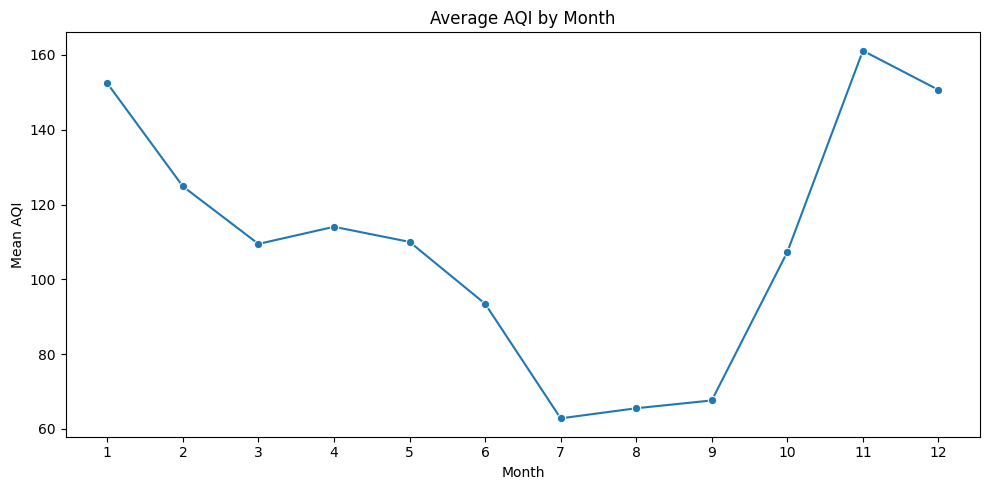

In [ ]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=data.groupby("month", as_index=False)["aqi_value"].mean(),
    x="month", y="aqi_value", marker="o"
)
plt.title("Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Mean AQI")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

### Average AQI by Month Observations

The monthly results show a strong temporal pattern. AQI is highest in November and December/January and lowest during the monsoon months, particularly July–September. This pattern is consistent with the seasonal summary and illustrates why time variables are useful predictors.


,count,mean,median,std
season,,,,
Winter,59302,143.128,122.000,80.894
Summer,63586,111.387,99.000,58.351
Monsoon,72893,72.121,61.000,42.902
Post-Monsoon,40004,134.352,115.000,82.409


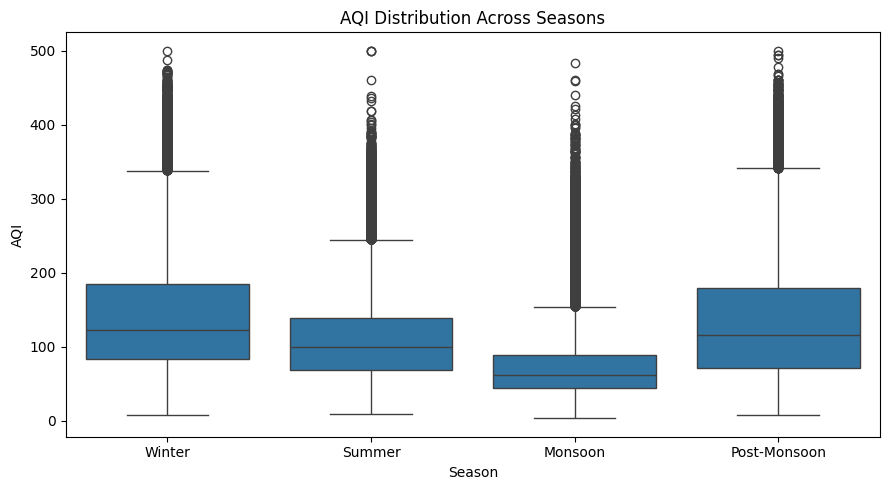

In [ ]:
season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

season_summary = (
    data.groupby("season")["aqi_value"]
    .agg(["count", "mean", "median", "std"])
    .reindex(season_order)
)

display(season_summary)

plt.figure(figsize=(9, 5))
sns.boxplot(data=data, x="season", y="aqi_value", order=season_order)
plt.title("AQI Distribution Across Seasons")
plt.xlabel("Season")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()

### AQI Distribution Across Seasons Observations

The executed seasonal summary shows the highest mean AQI in Winter (143.13), followed by Post-Monsoon (134.35), Summer (111.39) and Monsoon (72.12). Thus, the monsoon period has the lowest observed AQI, while winter has the highest.


## 16. Prominent-Pollutant Analysis

`prominent_pollutants` contains pollutant names or combinations of names. A single observation can therefore contain more than one pollutant.

For meaningful frequency analysis, the field is split and exploded into individual pollutant labels. This is used for descriptive analysis only; it is **not** treated as a numerical concentration.

### Prominent Pollutant Analysis

Investigates `prominent_pollutants` to find most frequent pollutants and their associated mean AQI (RQ4), offering insights into pollution types. Pollutants are split and exploded for frequency analysis.

In [ ]:
pollutant_data = data[["prominent_pollutants", "aqi_value"]].copy()

pollutant_data["pollutant_list"] = (
    pollutant_data["prominent_pollutants"]
    .fillna("Unknown")
    .astype(str)
    .str.replace(" ", "", regex=False)
    .str.split(",")
)

pollutant_long = pollutant_data.explode("pollutant_list")
pollutant_long = pollutant_long.rename(columns={"pollutant_list": "pollutant"})

pollutant_summary = (
    pollutant_long.groupby("pollutant")["aqi_value"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("count", ascending=False)
)

display(pollutant_summary)

,count,mean,median,std
pollutant,,,,
PM10,135806,96.122,85.000,53.782
PM2.5,78030,157.229,143.000,83.727
O3,24951,92.714,76.000,55.439
CO,18148,63.275,57.000,28.924
NO2,6025,77.846,66.000,48.506
SO2,5284,56.280,50.000,29.008
NH3,83,52.795,47.000,20.135
SO3,40,41.400,35.000,14.211


### Pollutant Summary Observations

PM10 and PM2.5 are the most frequently reported prominent-pollutant labels. Observations reporting PM2.5 as a prominent pollutant have a higher mean AQI than observations reporting PM10, O3 or CO.

These are **associations in the dataset**, not causal conclusions, because numerical pollutant concentrations are not available.


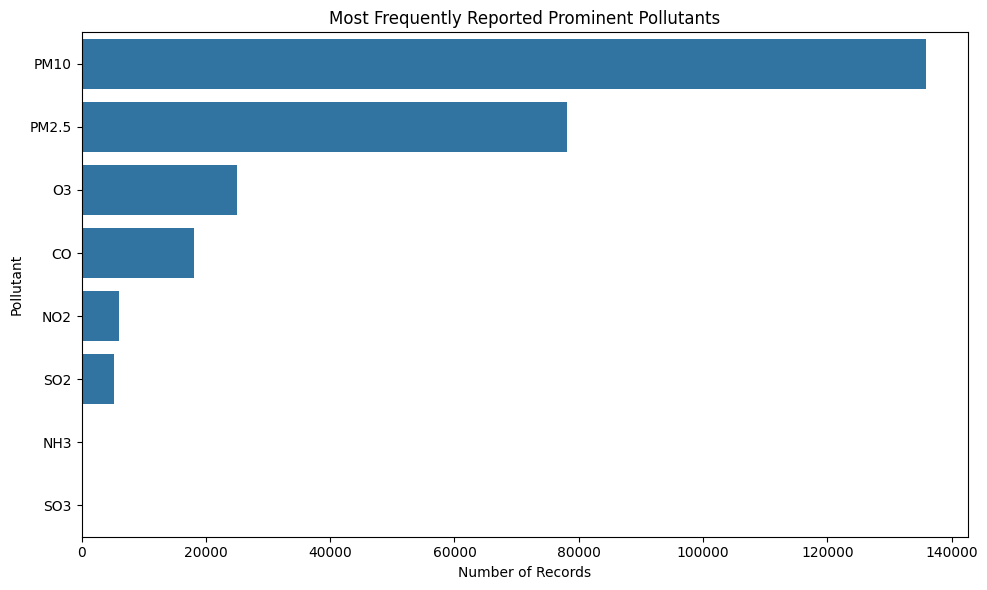

In [ ]:
top_pollutants = pollutant_summary.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_pollutants["count"], y=top_pollutants.index)
plt.title("Most Frequently Reported Prominent Pollutants")
plt.xlabel("Number of Records")
plt.ylabel("Pollutant")
plt.tight_layout()
plt.show()

### Most Frequent Pollutants Observations

The frequency plot confirms that PM10 and PM2.5 dominate the reported prominent-pollutant labels, followed by O3 and CO. This analysis describes reporting patterns; it does not establish pollutant causation or concentration levels.


## 17. Correlation Analysis

The available numerical variables are limited. Correlation is therefore performed on the numerical fields that actually exist rather than fabricating pollutant concentration measurements.

### Correlation Analysis

Examines linear relationships between numerical variables (`aqi_value`, `number_of_monitoring_stations`, `year`, `month`, `day_of_week`) to understand factors related to AQI (RQ5). Correlation analysis is limited because most available variables are categorical, and the dataset does not contain numerical concentrations of individual pollutants.

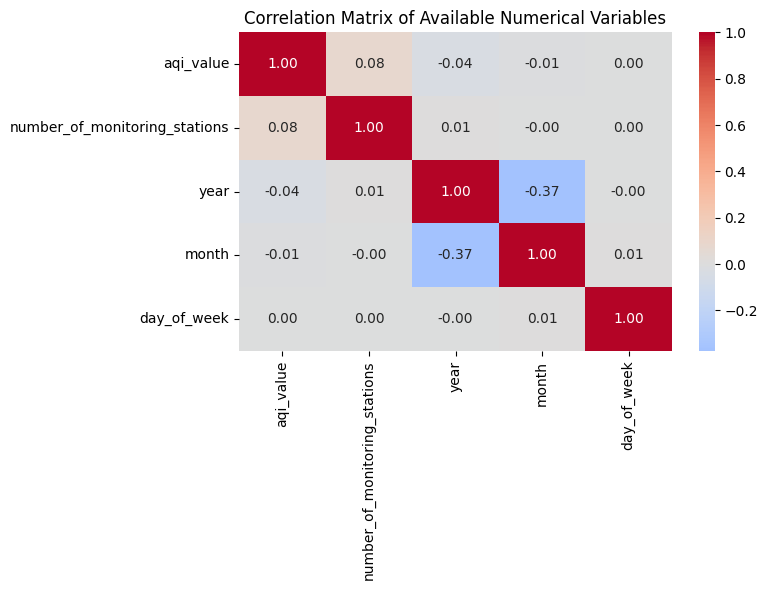

,aqi_value,number_of_monitoring_stations,year,month,day_of_week
aqi_value,1.000,0.077,-0.036,-0.010,0.002
number_of_monitoring_stations,0.077,1.000,0.006,-0.004,0.001
year,-0.036,0.006,1.000,-0.374,-0.003
month,-0.010,-0.004,-0.374,1.000,0.006
day_of_week,0.002,0.001,-0.003,0.006,1.000


In [ ]:
numeric_cols = ["aqi_value", "number_of_monitoring_stations", "year", "month", "day_of_week"]

corr = data[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Available Numerical Variables")
plt.tight_layout()
plt.show()

display(corr)

### Correlation Matrix Observations

The available numerical variables show weak linear relationships with AQI. The correlation between AQI and the number of monitoring stations is approximately **0.077**, while AQI has correlations of approximately **-0.036 with year**, **-0.010 with month**, and **0.002 with day of week**.

Correlation is limited here because most variables are categorical and the dataset does not contain numerical pollutant concentrations.


# 18. Statistical Analysis

All hypothesis tests use a significance level of:

**α = 0.05**

Decision rule:

- If **p < 0.05**, reject H₀.
- If **p ≥ 0.05**, fail to reject H₀.

Because this dataset is very large, statistical significance is interpreted together with the size and practical meaning of observed differences.

## 18.1 Confidence Interval for Mean AQI

**H₀/H₁ are not required for a confidence interval.**

We estimate a 95% confidence interval for the population mean AQI using the t-distribution.

In [ ]:
n = len(aqi)
mean_aqi = aqi.mean()
std_aqi = aqi.std(ddof=1)
sem = stats.sem(aqi)

ci_low, ci_high = stats.t.interval(
    confidence=0.95,
    df=n-1,
    loc=mean_aqi,
    scale=sem
)

print(f"Mean AQI = {mean_aqi:.3f}")
print(f"95% Confidence Interval = ({ci_low:.3f}, {ci_high:.3f})")

Mean AQI = 111.127
95% Confidence Interval = (110.839, 111.416)


### Confidence Interval for Mean AQI — Interpretation

The mean AQI is **111.127**, with a 95% confidence interval of approximately **110.839 to 111.416**. This interval provides a range of plausible values for the population mean represented by the sample.


## 18.2 Hypothesis Test – Seasonal Variation

**RQ3:** Does AQI vary significantly across seasons?

**H₀:** The mean AQI is equal across all seasons.

**H₁:** At least one season has a different mean AQI.

**Test:** One-way ANOVA

In [ ]:
season_groups = [
    data.loc[data["season"] == season, "aqi_value"]
    for season in season_order
]

season_f, season_p = f_oneway(*season_groups)

print(f"F-statistic = {season_f:.3f}")
print(f"p-value = {season_p:.6g}")

if season_p < 0.05:
    print("Decision: Reject H0.")
    print("Conclusion: AQI differs significantly across seasons.")
else:
    print("Decision: Fail to reject H0.")
    print("Conclusion: No statistically significant seasonal difference was detected.")

F-statistic = 15029.338
p-value < 0.001
Decision: Reject H0.
Conclusion: AQI differs significantly across seasons.


In [ ]:
# Note: `season_f` and `season_p` are expected to be defined by prior cell (e.g., 5bbf3475)
print(f"F-statistic = {season_f:.3f}")
# Report p-value as < 0.001 if it's practically zero
if season_p < 0.001:
    print("p-value < 0.001")
else:
    print(f"p-value = {season_p:.3f}")

if season_p < 0.05:
    print("Decision: Reject H0.")
    print("Conclusion: AQI differs significantly across seasons.")
else:
    print("Decision: Fail to reject H0.")
    print("Conclusion: No statistically significant seasonal difference was detected.")

F-statistic = 15029.338
p-value < 0.001
Decision: Reject H0.
Conclusion: AQI differs significantly across seasons.


In [ ]:
# Calculate Eta Squared for Seasonal ANOVA
# Note: `season_groups` and `mean_aqi` are expected to be defined by prior cells (e.g., 5bbf3475 and 0f33b040)
import numpy as np
ss_between = sum([len(group) * (group.mean() - mean_aqi)**2 for group in season_groups])
ss_total = sum([(x - mean_aqi)**2 for group in season_groups for x in group])
eta_squared_season = ss_between / ss_total

print(f"Eta Squared (eta²) = {eta_squared_season:.3f}")

# Interpretation of Eta Squared
if eta_squared_season < 0.01:
    print("Interpretation: Small effect size.")
elif eta_squared_season < 0.06:
    print("Interpretation: Medium effect size.")
else:
    print("Interpretation: Large effect size.")

Eta Squared (eta²) = 0.161
Interpretation: Large effect size.


### Seasonal ANOVA Result

The seasonal ANOVA gives **F = 15,029.338** with **p < 0.001**. Therefore, the null hypothesis that all seasonal mean AQIs are equal is rejected.

The result indicates a statistically significant difference in mean AQI across seasons.


### Seasonal ANOVA Interpretation

The very small p-value indicates statistically significant seasonal differences. However, statistical significance should be considered together with effect size and the actual differences in seasonal means.


## 18.3 Hypothesis Test – State-Wise Variation

**RQ3:** Does AQI vary significantly across Indian states/regions?

**H₀:** All states have the same mean AQI.

**H₁:** At least one state has a different mean AQI.

**Test:** One-way ANOVA

In [ ]:
state_groups = [
    group["aqi_value"].values
    for _, group in data.groupby("state")
]

state_f, state_p = f_oneway(*state_groups)

print(f"F-statistic = {state_f:.3f}")
print(f"p-value = {state_p:.6g}")

if state_p < 0.05:
    print("Decision: Reject H0.")
    print("Conclusion: Mean AQI differs significantly across states/regions.")
else:
    print("Decision: Fail to reject H0.")
    print("Conclusion: No statistically significant state-wise difference was detected.")

F-statistic = 1674.436
p-value < 0.001
Decision: Reject H0.
Conclusion: Mean AQI differs significantly across states/regions.


In [ ]:
# Note: `state_f` and `state_p` are expected to be defined by prior cell (e.g., 5d2dbc74)
print(f"F-statistic = {state_f:.3f}")
# Report p-value as < 0.001 if it's practically zero
if state_p < 0.001:
    print("p-value < 0.001")
else:
    print(f"p-value = {state_p:.3f}")

if state_p < 0.05:
    print("Decision: Reject H0.")
    print("Conclusion: Mean AQI differs significantly across states/regions.")
else:
    print("Decision: Fail to reject H0.")
    print("Conclusion: No statistically significant state-wise difference was detected.")

F-statistic = 1674.436
p-value < 0.001
Decision: Reject H0.
Conclusion: Mean AQI differs significantly across states/regions.


In [ ]:
# Calculate Eta Squared for State-wise ANOVA
# Note: `state_groups` is expected to be defined by prior cell (e.g., 5d2dbc74)
import numpy as np
all_aqi = np.concatenate(state_groups)
mean_all_aqi = all_aqi.mean()

ss_between_state = sum([len(group) * (group.mean() - mean_all_aqi)**2 for group in state_groups])
ss_total_state = sum([(x - mean_all_aqi)**2 for group in state_groups for x in group])
eta_squared_state = ss_between_state / ss_total_state

print(f"Eta Squared (eta²) = {eta_squared_state:.3f}")

# Interpretation of Eta Squared
if eta_squared_state < 0.01:
    print("Interpretation: Small effect size.")
elif eta_squared_state < 0.06:
    print("Interpretation: Medium effect size.")
else:
    print("Interpretation: Large effect size.")

Eta Squared (eta²) = 0.180
Interpretation: Large effect size.


### State-Wise ANOVA Result

The state-wise ANOVA gives **F = 1,674.436** with **p < 0.001**. Therefore, the null hypothesis that all state/region mean AQIs are equal is rejected.

The result indicates statistically significant differences in mean AQI across states/regions.


### Statistical Caution

A very large sample can produce extremely small p-values. Therefore, the project reports **effect size (η²)** along with the ANOVA p-value.

For the executed data:
- Seasonal η² = **0.161** → large effect
- State-wise η² = **0.180** → large effect

ANOVA establishes that at least one group differs; Tukey HSD is used to examine pairwise seasonal differences.


### Post-Hoc Analysis for Seasonal ANOVA: Tukey HSD

Since the overall ANOVA for seasonal variation was significant, we can perform a post-hoc Tukey HSD test to identify which specific seasonal pairs have statistically significant differences in mean AQI. This helps pinpoint the nature of the seasonal variation.

In [ ]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import numpy as np

# Create a single array of AQI values and a corresponding array of season labels
# Note: `season_groups` and `season_order` are expected to be defined by prior cells (e.g., 5bbf3475 and c04616c5)
all_aqi_values = np.concatenate(season_groups)
all_season_labels = []
for i, season in enumerate(season_order):
    all_season_labels.extend([season] * len(season_groups[i]))

# Perform Tukey HSD post-hoc test
tukey_result = pairwise_tukeyhsd(endog=all_aqi_values, groups=all_season_labels, alpha=0.05)

print(tukey_result)

      Multiple Comparison of Means - Tukey HSD, FWER=0.05       
   group1       group2    meandiff p-adj  lower   upper   reject
----------------------------------------------------------------
     Monsoon Post-Monsoon  62.2306   0.0 61.1842   63.277   True
     Monsoon       Summer  39.2659   0.0 38.3533  40.1785   True
     Monsoon       Winter  71.0073   0.0 70.0773  71.9373   True
Post-Monsoon       Summer -22.9647   0.0 -24.038 -21.8915   True
Post-Monsoon       Winter   8.7767   0.0  7.6886   9.8648   True
      Summer       Winter  31.7414   0.0 30.7814  32.7015   True
----------------------------------------------------------------


### Tukey HSD Results Observations

The executed Tukey HSD test indicates that **all six seasonal pairwise comparisons are statistically significant** at α = 0.05.

This means the mean AQI differs significantly for every pair among Winter, Summer, Monsoon and Post-Monsoon in this dataset.


# 19. Multiple Linear Regression – AQI Prediction

### Target
`aqi_value`

### Predictors
- State
- Season
- Month
- Day of week
- Number of monitoring stations

The model does not use `air_quality_status`, `prominent_pollutants`, or AQI-derived variables to avoid target leakage.

A chronological split is used:

- **Training:** observations before 1 January 2024
- **Testing:** observations from 1 January 2024 onward

This better represents prediction on future observations.

### Train-Test Split Explanation

For both regression and classification tasks, the dataset was divided into training and testing sets using a chronological split. Observations before January 1, 2024, were used for training, and observations from January 1, 2024, onward were used for testing. This approach simulates a real-world scenario where a model is trained on historical data to predict future values. A random state of 42 was used where applicable to ensure reproducibility. For classification, `stratify=y` was used during the split to ensure that the proportion of target classes is maintained in both training and testing sets, which is crucial given the potential for class imbalance in `air_quality_status`.

In [ ]:
# Regression dataset
reg_df = data[
    ["date", "state", "season", "month", "day_of_week",
     "number_of_monitoring_stations", "aqi_value"]
].copy()

train_reg = reg_df[reg_df["date"] < "2024-01-01"].copy()
test_reg = reg_df[reg_df["date"] >= "2024-01-01"].copy()

features_reg = [
    "state", "season", "month", "day_of_week",
    "number_of_monitoring_stations"
]
target_reg = "aqi_value"

X_train_reg = train_reg[features_reg]
y_train_reg = train_reg[target_reg]
X_test_reg = test_reg[features_reg]
y_test_reg = test_reg[target_reg]

categorical_reg = ["state", "season"]
numeric_reg = ["month", "day_of_week", "number_of_monitoring_stations"]

preprocess_reg = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_reg),
    ("num", "passthrough", numeric_reg)
])

linear_model = Pipeline([
    ("preprocess", preprocess_reg),
    ("model", LinearRegression())
])

linear_model.fit(X_train_reg, y_train_reg)
pred_linear = linear_model.predict(X_test_reg)

mae_linear = mean_absolute_error(y_test_reg, pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test_reg, pred_linear))
r2_linear = r2_score(y_test_reg, pred_linear)

print("Multiple Linear Regression Results")
print(f"MAE  : {mae_linear:.3f}")
print(f"RMSE : {rmse_linear:.3f}")
print(f"R²   : {r2_linear:.3f}")

Multiple Linear Regression Results
MAE  : 43.912
RMSE : 56.124
R²   : 0.230


### Multiple Linear Regression Results

- **MAE:** 43.912
- **RMSE:** 56.124
- **R²:** 0.230

The model explains approximately **23.0% of the variation in test-set AQI** using the available geographical, temporal and monitoring-station features.


## 19.2 Baseline Regression Model


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Note: `y_test_reg` and `y_train_reg` are expected to be defined by prior cell (e.g., 1022cea7)
baseline_prediction = np.full_like(y_test_reg, y_train_reg.mean())

mae_baseline = mean_absolute_error(y_test_reg, baseline_prediction)
rmse_baseline = np.sqrt(mean_squared_error(y_test_reg, baseline_prediction))
r2_baseline = r2_score(y_test_reg, baseline_prediction)

print("Baseline Regression Model (Mean Prediction)")
print(f"MAE  : {mae_baseline:.3f}")
print(f"RMSE : {rmse_baseline:.3f}")
print(f"R²   : {r2_baseline:.3f}")

Baseline Regression Model (Mean Prediction)
MAE  : 50.725
RMSE : 64.301
R²   : -0.011


### Baseline Model Observations

The mean-prediction baseline gives:
- **MAE:** 50.725
- **RMSE:** 64.301
- **R²:** -0.011

Multiple Linear Regression improves on this baseline, showing that the available predictors capture some useful signal even though the overall predictive power remains limited.


## 19.3 Regression Diagnostics


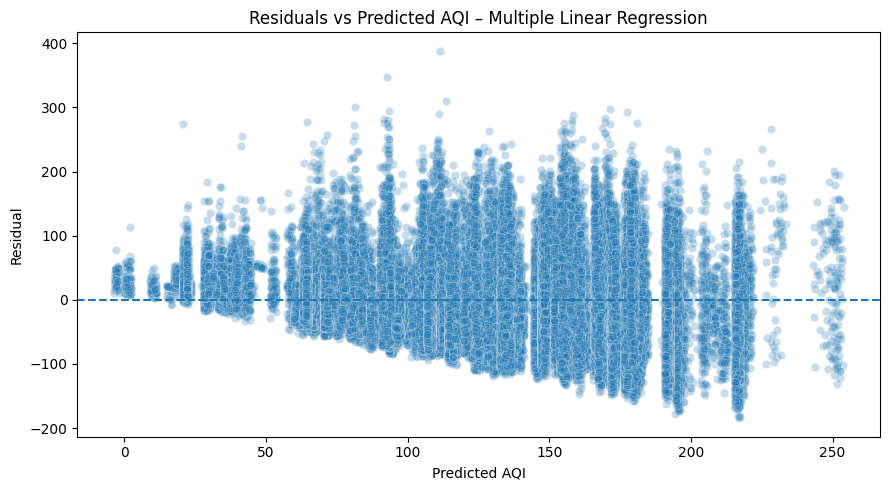

In [ ]:
residuals = y_test_reg - pred_linear

plt.figure(figsize=(9, 5))
sns.scatterplot(x=pred_linear, y=residuals, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted AQI – Multiple Linear Regression")
plt.xlabel("Predicted AQI")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

### Residuals vs Predicted AQI Observations

1.  **Heteroscedasticity:** Residuals spread increases with predicted AQI, showing non-constant errors.
2.  **Non-Linearity:** Residuals are not randomly scattered, suggesting the linear model misses non-linear relationships.
3.  **Model Bias:** The plot confirms the linear model's assumptions are violated, especially at higher AQI predictions.

## 20. Random Forest Regression – Comparison Model


In [ ]:
rf_reg = Pipeline([
    ("preprocess", preprocess_reg),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        max_depth=20,
        min_samples_leaf=2
    ))
])

rf_reg.fit(X_train_reg, y_train_reg)
pred_rf_reg = rf_reg.predict(X_test_reg)

mae_rf_reg = mean_absolute_error(y_test_reg, pred_rf_reg)
rmse_rf_reg = np.sqrt(mean_squared_error(y_test_reg, pred_rf_reg))
r2_rf_reg = r2_score(y_test_reg, pred_rf_reg)

print("Random Forest Regression Results")
print(f"MAE  : {mae_rf_reg:.3f}")
print(f"RMSE : {rmse_rf_reg:.3f}")
print(f"R²   : {r2_rf_reg:.3f}")

Random Forest Regression Results
MAE  : 41.057
RMSE : 55.709
R²   : 0.241


### Random Forest Regression Results

- **MAE:** 41.057
- **RMSE:** 55.709
- **R²:** 0.241

Random Forest performs slightly better than Multiple Linear Regression on all three reported regression metrics: it has lower MAE, lower RMSE and higher R².

However, the R² is still modest, so the available predictors do not explain most AQI variation.


## 20.1 Random Forest Regression – Feature Importance


,Feature,Importance
33,month,0.400
2,state_Bihar,0.157
11,state_Karnataka,0.094
7,state_Haryana,0.051
35,number_of_monitoring_stations,0.040
27,state_Uttar Pradesh,0.027
24,state_Tamil Nadu,0.026
34,day_of_week,0.025
30,season_Post-Monsoon,0.023
32,season_Winter,0.019


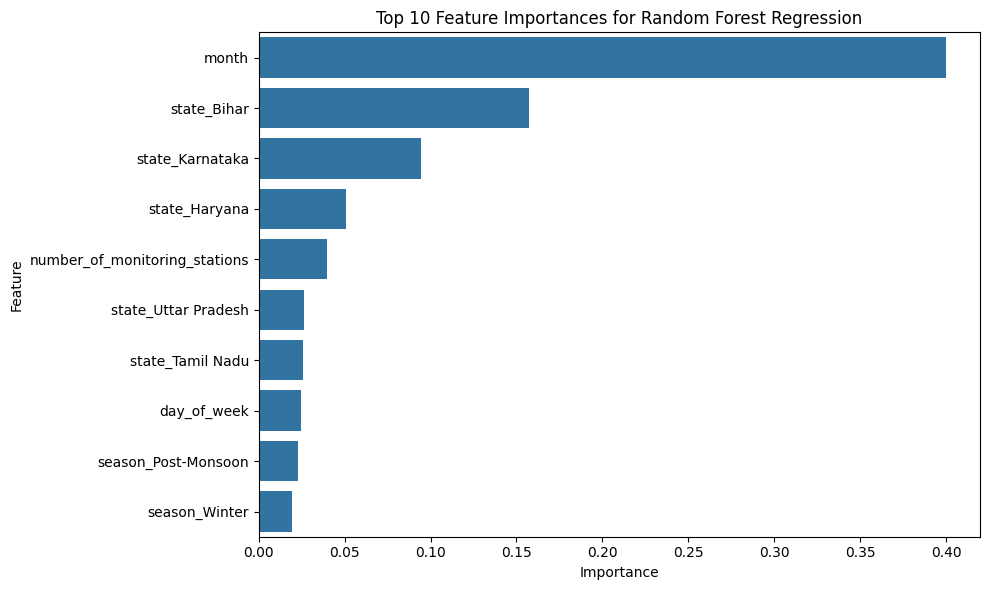

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Note: `rf_reg`, `categorical_reg`, `numeric_reg` are expected to be defined by prior cells (e.g., d1d839dc and 1022cea7)
importances = rf_reg.named_steps['model'].feature_importances_

# Get feature names from the preprocessor
one_hot_features = rf_reg.named_steps['preprocess'].named_transformers_['cat'].get_feature_names_out(categorical_reg)
all_features = np.concatenate([one_hot_features, numeric_reg])

feature_importance_df = pd.DataFrame({
    'Feature': all_features,
    'Importance': importances
}).sort_values('Importance', ascending=False)

display(feature_importance_df.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10))
plt.title('Top 10 Feature Importances for Random Forest Regression')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### Feature Importance Observations

The executed Random Forest feature-importance output shows **month** as the most influential feature, followed by several state indicators and the number of monitoring stations.

Feature importance indicates how useful variables were to this trained Random Forest model; it does **not** establish causation.


### Interpretation of Limited Predictive Performance

The regression models demonstrate the application of machine learning techniques but show limited predictive accuracy. This is likely because the dataset does not contain numerical concentrations of important pollutants such as PM2.5, PM10, NO₂, SO₂, CO and O₃, which are major determinants of AQI. Without these key drivers, the models rely on proxy variables (location, time, monitoring stations) that cannot fully explain the complex variations in AQI.

# 21. Air-Quality Status Classification


### Target Leakage Prevention

**Very Important:** The `aqi_value` variable was explicitly excluded from classification features because the air-quality status is defined based on AQI ranges. Including `aqi_value` as a predictor would result in target leakage and artificially inflate classification performance, making the model invalid for real-world application.

In [ ]:
clf_df = data[
    ["date", "state", "season", "month", "day_of_week",
     "number_of_monitoring_stations", "air_quality_status"]
].copy()

train_clf = clf_df[clf_df["date"] < "2024-01-01"].copy()
test_clf = clf_df[clf_df["date"] >= "2024-01-01"].copy()

features_clf = [
    "state", "season", "month", "day_of_week",
    "number_of_monitoring_stations"
]
target_clf = "air_quality_status"

X_train_clf = train_clf[features_clf]
y_train_clf = train_clf[target_clf]
X_test_clf = test_clf[features_clf]
y_test_clf = test_clf[target_clf]

categorical_clf = ["state", "season"]
numeric_clf = ["month", "day_of_week", "number_of_monitoring_stations"]

preprocess_clf = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_clf),
    ("num", StandardScaler(), numeric_clf)
])

### Class Imbalance Analysis

The distribution of the target variable `air_quality_status` was examined to identify potential class imbalance. Understanding this imbalance is crucial because it can significantly affect model training and evaluation, particularly for minority classes that might be underrepresented.

In [ ]:
import pandas as pd

print('Class distribution of air_quality_status:')
display(data['air_quality_status'].value_counts().to_frame('Count'))
display((data['air_quality_status'].value_counts(normalize=True) * 100).to_frame('Percentage'))

print('\nInterpretation: The class distribution shows significant imbalance, with \'Satisfactory\' and \'Moderate\' being the most frequent classes. This justifies the use of `class_weight=\"balanced\"` in classification models and the reporting of metrics like F1-score which are robust to imbalance.')

Class distribution of air_quality_status:


,Count
air_quality_status,
Satisfactory,88897
Moderate,77537
Good,41971
Poor,21154
Very Poor,5671
Severe,555


,Percentage
air_quality_status,
Satisfactory,37.703
Moderate,32.885
Good,17.801
Poor,8.972
Very Poor,2.405
Severe,0.235



Interpretation: The class distribution shows significant imbalance, with 'Satisfactory' and 'Moderate' being the most frequent classes. This justifies the use of `class_weight="balanced"` in classification models and the reporting of metrics like F1-score which are robust to imbalance.


## 21.1 Logistic Regression


In [ ]:
logistic_model = Pipeline([
    ("preprocess", preprocess_clf),
    ("model", LogisticRegression(
        max_iter=500,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train_clf, y_train_clf)
pred_logistic = logistic_model.predict(X_test_clf)

acc_log = accuracy_score(y_test_clf, pred_logistic)
prec_log = precision_score(y_test_clf, pred_logistic, average="weighted", zero_division=0)
rec_log = recall_score(y_test_clf, pred_logistic, average="weighted", zero_division=0)
f1_log = f1_score(y_test_clf, pred_logistic, average="weighted", zero_division=0)

print("Logistic Regression")
print(f"Accuracy : {acc_log:.3f}")
print(f"Precision: {prec_log:.3f}")
print(f"Recall   : {rec_log:.3f}")
print(f"F1-score : {f1_log:.3f}")

Logistic Regression
Accuracy : 0.394
Precision: 0.502
Recall   : 0.394
F1-score : 0.427


In [ ]:
from sklearn.metrics import f1_score

f1_log_macro = f1_score(y_test_clf, pred_logistic, average="macro", zero_division=0)
print(f"F1-macro : {f1_log_macro:.3f}")

F1-macro : 0.283


### Logistic Regression Results Observations

- **Accuracy:** 0.394
- **Weighted Precision:** 0.502
- **Weighted Recall:** 0.394
- **Weighted F1:** 0.427
- **Macro F1:** 0.283

The gap between weighted and macro F1 reflects the difficulty of treating all six classes equally when the class distribution is imbalanced.


## 21.2 Random Forest Classifier


In [ ]:
rf_clf = Pipeline([
    ("preprocess", preprocess_clf),
    ("model", RandomForestClassifier(
        n_estimators=120,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced",
        max_depth=20,
        min_samples_leaf=2
    ))
])

rf_clf.fit(X_train_clf, y_train_clf)
pred_rf_clf = rf_clf.predict(X_test_clf)

acc_rf = accuracy_score(y_test_clf, pred_rf_clf)
prec_rf = precision_score(y_test_clf, pred_rf_clf, average="weighted", zero_division=0)
rec_rf = recall_score(y_test_clf, pred_rf_clf, average="weighted", zero_division=0)
f1_rf = f1_score(y_test_clf, pred_rf_clf, average="weighted", zero_division=0)

print("Random Forest Classifier")
print(f"Accuracy : {acc_rf:.3f}")
print(f"Precision: {prec_rf:.3f}")
print(f"Recall   : {rec_rf:.3f}")
print(f"F1-score : {f1_rf:.3f}")

Random Forest Classifier
Accuracy : 0.412
Precision: 0.493
Recall   : 0.412
F1-score : 0.429


In [ ]:
from sklearn.metrics import f1_score

f1_rf_macro = f1_score(y_test_clf, pred_rf_clf, average="macro", zero_division=0)
print(f"F1-macro : {f1_rf_macro:.3f}")

F1-macro : 0.294


### Random Forest Classifier Results Observations

- **Accuracy:** 0.412
- **Weighted Precision:** 0.493
- **Weighted Recall:** 0.412
- **Weighted F1:** 0.429
- **Macro F1:** 0.294

Random Forest is slightly better than Logistic Regression on accuracy, weighted F1 and macro F1, although both models struggle with minority categories.


## 22. Classification Reports


In [ ]:
print("Logistic Regression Classification Report")
print(classification_report(y_test_clf, pred_logistic, zero_division=0))

print("\nRandom Forest Classification Report")
print(classification_report(y_test_clf, pred_rf_clf, zero_division=0))

Logistic Regression Classification Report
              precision    recall  f1-score   support

        Good       0.47      0.61      0.53     19799
    Moderate       0.54      0.41      0.47     40148
        Poor       0.16      0.25      0.20      9260
Satisfactory       0.57      0.31      0.40     44239
      Severe       0.00      0.54      0.01        68
   Very Poor       0.05      0.38      0.09      1561

    accuracy                           0.39    115075
   macro avg       0.30      0.42      0.28    115075
weighted avg       0.50      0.39      0.43    115075


Random Forest Classification Report
              precision    recall  f1-score   support

        Good       0.48      0.59      0.53     19799
    Moderate       0.51      0.46      0.48     40148
        Poor       0.18      0.41      0.25      9260
Satisfactory       0.57      0.29      0.39     44239
      Severe       0.00      0.31      0.01        68
   Very Poor       0.07      0.24      0.10      1561

### Classification Reports Observations

Both classifiers perform better on the more frequent categories than on the rare categories.

The **Severe** class is particularly difficult: it has very few test observations and receives an F1-score of approximately 0.01 for both models. This illustrates why macro F1 is important in addition to accuracy and weighted F1.


## 23. Confusion Matrices


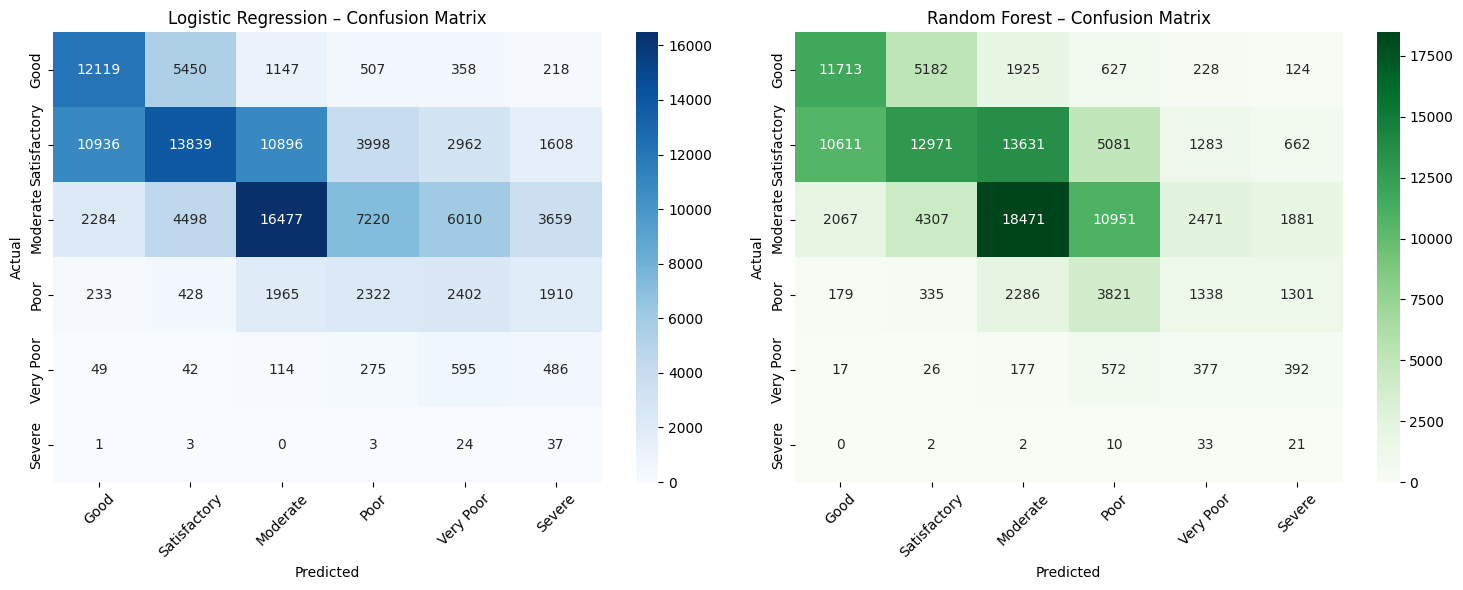

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cm_log = confusion_matrix(y_test_clf, pred_logistic, labels=status_order)
cm_rf = confusion_matrix(y_test_clf, pred_rf_clf, labels=status_order)

sns.heatmap(cm_log, annot=True, fmt="d", cmap="Blues",
            xticklabels=status_order, yticklabels=status_order, ax=axes[0])
axes[0].set_title("Logistic Regression – Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens",
            xticklabels=status_order, yticklabels=status_order, ax=axes[1])
axes[1].set_title("Random Forest – Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Confusion Matrices Observations

The confusion matrices show substantial overlap between adjacent air-quality categories. The minority classes, especially Severe and Very Poor, are frequently misclassified.

This confirms that classification is difficult when AQI itself is excluded to prevent target leakage.


# 24. Model Comparison


In [ ]:
regression_comparison = pd.DataFrame({
    "Model": ["Multiple Linear Regression", "Random Forest Regression"],
    "MAE": [mae_linear, mae_rf_reg],
    "RMSE": [rmse_linear, rmse_rf_reg],
    "R2": [r2_linear, r2_rf_reg]
})

classification_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest Classifier"],
    "Accuracy": [acc_log, acc_rf],
    "Precision": [prec_log, prec_rf],
    "Recall": [rec_log, rec_rf],
    "F1": [f1_log, f1_rf]
})

print("Regression model comparison")
display(regression_comparison)

print("Classification model comparison")
display(classification_comparison)

Regression model comparison


,Model,MAE,RMSE,R2
0,Multiple Linear Regression,43.912,56.124,0.230
1,Random Forest Regression,41.057,55.709,0.241


Classification model comparison


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.394,0.502,0.394,0.427
1,Random Forest Classifier,0.412,0.493,0.412,0.429


### Model Comparison Observations

**Regression**
- Baseline: MAE 50.725, RMSE 64.301, R² -0.011
- Multiple Linear Regression: MAE 43.912, RMSE 56.124, R² 0.230
- Random Forest Regression: MAE 41.057, RMSE 55.709, R² 0.241

Random Forest gives the best regression performance among the tested models, while both machine-learning models improve substantially over the mean baseline.

**Classification**
- Logistic Regression: Accuracy 0.394, Weighted F1 0.427, Macro F1 0.283
- Random Forest Classifier: Accuracy 0.412, Weighted F1 0.429, Macro F1 0.294

Random Forest is slightly better overall, but both classifiers struggle with minority AQI-status categories.


# 25. Key Findings

The major findings obtained from the statistical analysis and machine-learning models are:

1. **Overall AQI:** The dataset contains **235,785 observations** with a mean AQI of **111.127**, median of **92**, and IQR of **83**, indicating a right-skewed distribution with substantial variation in air quality.

2. **Air-quality categories:** Most observations fall under **Satisfactory (88,897)** and **Moderate (77,537)**, while **Severe (555)** is the smallest class. This class imbalance affects classification performance, particularly for minority categories.

3. **Regional variation:** **Delhi** has the highest mean AQI among the states/regions in the analysis (**206.417**), showing substantial geographic variation in air quality.

4. **Seasonal variation:** Mean AQI is highest in **Winter (143.128)** and lowest in **Monsoon (72.121)**. One-way ANOVA indicates that seasonal differences are statistically significant (**p < 0.001**), with a large effect size (**eta-squared = 0.161**).

5. **State-level variation:** AQI also differs significantly across states/regions (**p < 0.001**), with a large effect size (**eta-squared = 0.180**).

6. **Pollutant labels:** **PM10** is the most frequently reported prominent pollutant label, followed by **PM2.5**. These are descriptive pollutant labels; the dataset does not contain numerical pollutant concentration measurements.

7. **AQI regression:** Random Forest Regression gives the best regression performance among the tested models, with **MAE = 41.057, RMSE = 55.709 and R² = 0.241**, slightly outperforming Multiple Linear Regression (**MAE = 43.912, RMSE = 56.124, R² = 0.230**) and clearly improving over the mean baseline.

8. **Classification:** Random Forest Classifier achieves **41.2% accuracy** and **0.429 weighted F1**, slightly better than Logistic Regression (**39.4% accuracy** and **0.427 weighted F1**). However, the **macro F1 of 0.294** indicates limited performance across all classes, especially the rare Severe and Very Poor categories.

9. **Feature importance:** In the Random Forest regression model, **month** is the most influential feature, followed by state-related features and the number of monitoring stations. These importances indicate predictive association, not causation.

10. **Overall interpretation:** The analysis demonstrates strong spatial and seasonal differences in AQI, while prediction using the available non-leaking variables has **limited but measurable predictive ability**. The results support the usefulness of statistical analysis for identifying air-quality patterns while highlighting the need for richer pollutant-concentration and meteorological data for more accurate prediction.


# 26. Limitations

1. The dataset does not provide numerical concentrations for individual pollutants.
2. Therefore, direct pollutant-concentration-to-AQI modeling cannot be performed from this file alone.
3. `prominent_pollutants` is a categorical/descriptive field and must not be interpreted as a concentration measurement.
4. `air_quality_status` is derived from AQI bands, so `aqi_value` is excluded from classification to prevent target leakage.
5. The chronological train-test split is appropriate for future-style prediction but does not preserve a fixed 80:20 ratio.
6. Large sample sizes can produce extremely small p-values; effect size and descriptive differences should therefore accompany hypothesis tests.
7. Correlation measures linear association and does not imply causation.
8. Important explanatory variables such as pollutant concentrations and meteorological measurements are unavailable, limiting predictive performance.


# 27. Conclusion

This project presents a statistical and machine-learning-based analysis of air quality across Indian regions using AQI observations in the supplied dataset. The study examines AQI distribution, geographical and temporal variation, prominent pollutant labels, and differences across seasons and states.

Descriptive analysis shows substantial variation in AQI, with a mean of approximately 111.13 and a median of 92.00. Seasonal and state-wise ANOVA results are statistically significant (**p < 0.001**), with large eta-squared effect sizes, indicating meaningful group-level differences in the observed data. Tukey HSD further shows significant pairwise differences among the seasons.

For numerical AQI prediction, the mean baseline is outperformed by both machine-learning models. Multiple Linear Regression achieves an R² of 0.230, while Random Forest Regression achieves an R² of 0.241 with lower MAE and RMSE. This indicates that the available geographical, temporal and monitoring-station variables contain useful predictive information, but they do not explain most AQI variation.

For air-quality-status classification, AQI itself is excluded to prevent direct target leakage because the status is defined from AQI ranges. Random Forest Classification performs slightly better than Logistic Regression, but both models have difficulty predicting minority categories, particularly Severe and Very Poor. Macro F1 therefore provides an important complementary measure to weighted F1 and accuracy.

Overall, the project demonstrates a complete Statistical Machine Learning workflow involving descriptive statistics, exploratory analysis, confidence intervals, hypothesis testing, effect size, post-hoc analysis, regression, classification and model evaluation. The major limitation is the absence of numerical pollutant concentration and meteorological variables. Future work can improve prediction by incorporating measurements such as PM2.5, PM10, NO₂, SO₂, CO and O₃ together with temperature, humidity and wind speed.
